--- Baseline Metrics ---
Clean Image Sharpness: 698.84

--- Task 1: Averaging (Noise Suppression) ---
Sigma 10, Kernel 3x3 -> PSNR: 28.47 | Sharpness: 111.90
Sigma 25, Kernel 3x3 -> PSNR: 25.77 | Sharpness: 239.62
Sigma 10, Kernel 5x5 -> PSNR: 26.36 | Sharpness: 49.63
Sigma 25, Kernel 5x5 -> PSNR: 24.98 | Sharpness: 74.01
Sigma 10, Kernel 9x9 -> PSNR: 23.82 | Sharpness: 31.18
Sigma 25, Kernel 9x9 -> PSNR: 23.10 | Sharpness: 35.26

--- Task 2: Laplacian Sharpening (Boundary Recovery) ---
Laplacian 4-neighbor -> PSNR: 23.67 | Sharpness: 1266.37
Laplacian 8-neighbor -> PSNR: 22.68 | Sharpness: 1854.81

--- Task 3: High-Boost Filtering ---
Boost k=1 -> PSNR: 23.07 | Sharpness: 6315.29
Boost k=1.5 -> PSNR: 20.85 | Sharpness: 9344.17
Boost k=2 -> PSNR: 19.31 | Sharpness: 12602.60
Boost k=3 -> PSNR: 17.20 | Sharpness: 20088.14


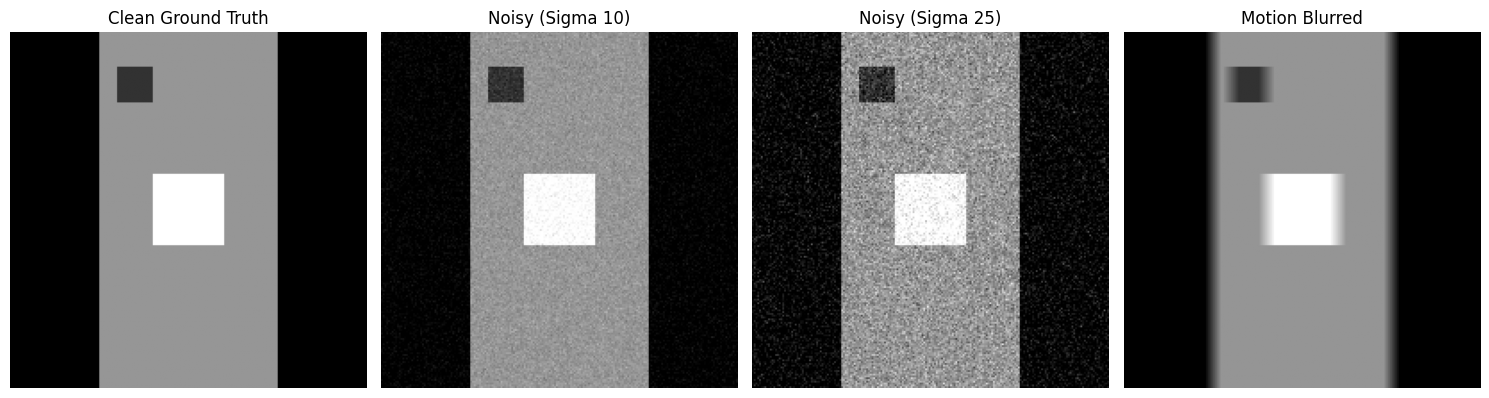

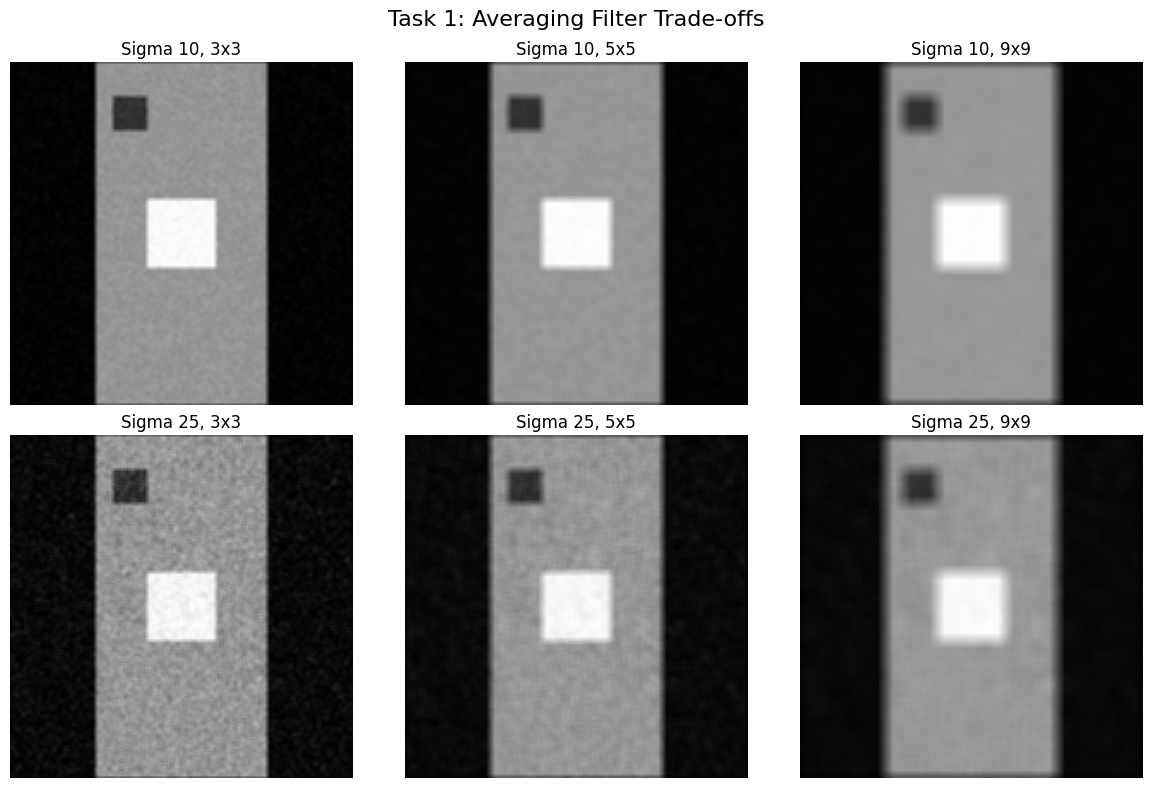

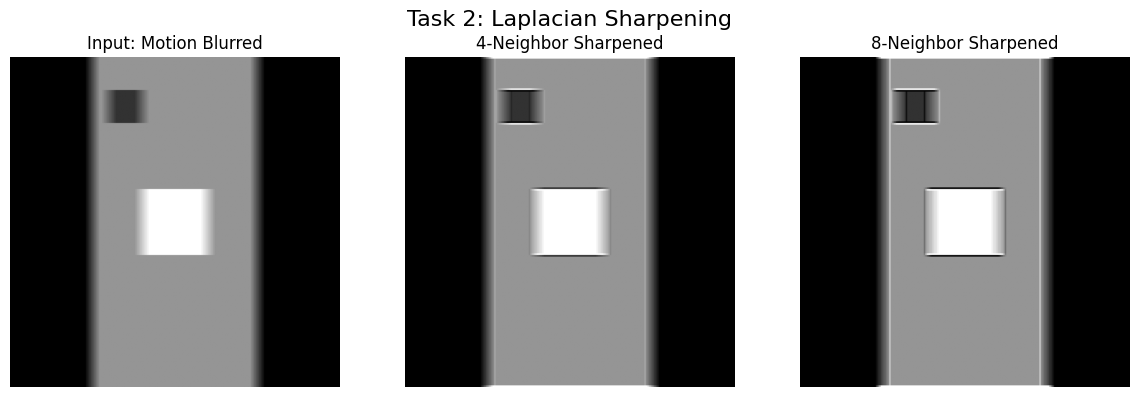

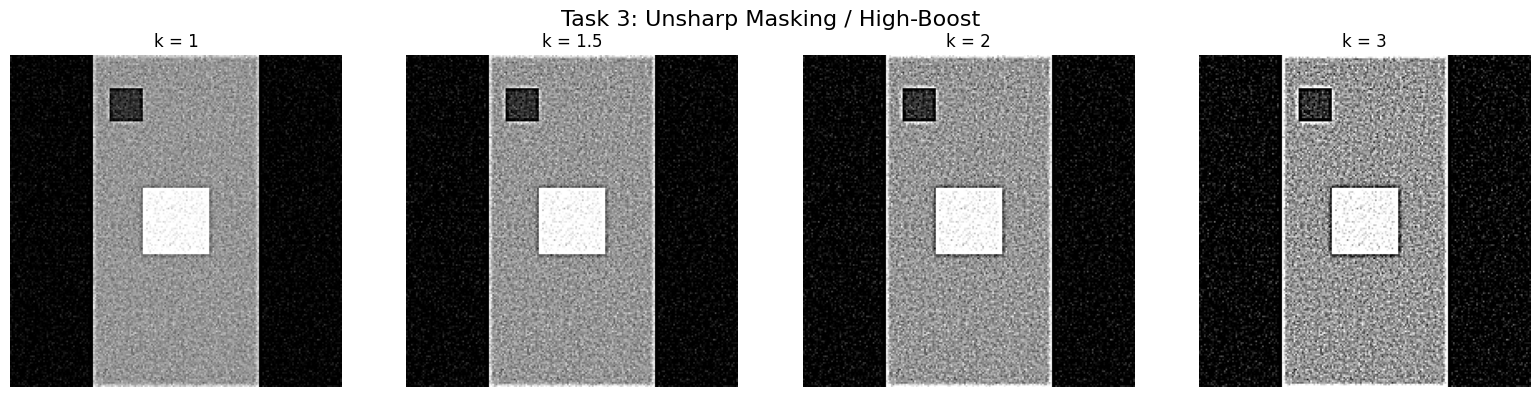

In [1]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

# ==========================================
# FROM-SCRATCH FILTERING IMPLEMENTATION
# ==========================================
def correlate2d_custom(image, kernel):
    """
    Implements 2D spatial correlation from first principles.
    No cv2.filter2D or scipy.signal functions are used.
    """
    # Ensure float operations to prevent overflow/underflow during intermediate steps
    image = image.astype(np.float64)
    kernel = kernel.astype(np.float64)
    
    k_h, k_w = kernel.shape
    img_h, img_w = image.shape
    
    # Calculate padding sizes
    pad_h, pad_w = k_h // 2, k_w // 2
    
    # Pad the image with zeros
    padded_img = np.pad(image, ((pad_h, pad_h), (pad_w, pad_w)), mode='constant', constant_values=0)
    
    # Initialize output image
    output = np.zeros_like(image)
    
    # Perform correlation via nested loops mapping kernel to image regions
    for i in range(img_h):
        for j in range(img_w):
            region = padded_img[i:i+k_h, j:j+k_w]
            output[i, j] = np.sum(region * kernel)
            
    return output

# ==========================================
# METRICS
# ==========================================
def calculate_psnr(original, processed):
    """Calculates Peak Signal-to-Noise Ratio (PSNR)."""
    mse = np.mean((original.astype(np.float64) - processed.astype(np.float64)) ** 2)
    if mse == 0:
        return float('inf')
    max_pixel = 255.0
    psnr = 20 * np.log10(max_pixel / np.sqrt(mse))
    return psnr

def calculate_sharpness(image):
    """
    Sharpness metric: Variance of the Laplacian.
    Measures edge strength across the image.
    """
    laplacian_kernel = np.array([[0, 1, 0], [1, -4, 1], [0, 1, 0]])
    laplacian_response = correlate2d_custom(image, laplacian_kernel)
    return np.var(laplacian_response)

# ==========================================
# DATA DEGRADATION (Test Data Generation)
# ==========================================
def add_gaussian_noise(image, sigma):
    """Adds Gaussian noise to simulate sensor/thermal grain."""
    noise = np.random.normal(0, sigma, image.shape)
    noisy_img = image.astype(np.float64) + noise
    return np.clip(noisy_img, 0, 255).astype(np.uint8)

def add_motion_blur(image, length=9):
    """Adds linear motion blur to simulate vehicle vibration."""
    # Create horizontal motion blur kernel
    kernel = np.zeros((length, length))
    kernel[length // 2, :] = 1.0 / length
    
    blurred = correlate2d_custom(image, kernel)
    return np.clip(blurred, 0, 255).astype(np.uint8)

# ==========================================
# MAIN LAB EXECUTION
# ==========================================
def main():
    # ---------------------------------------------------------
    # 0. Acquire Clean Ground Truth Image
    # ---------------------------------------------------------
    # Create a synthetic AGV scene (a corridor/path with obstacles)
    # Alternatively, load your own: clean_img = cv2.imread('your_image.jpg', cv2.IMREAD_GRAYSCALE)
    clean_img = np.zeros((200, 200), dtype=np.uint8)
    clean_img[:, 50:150] = 150  # Grey path
    clean_img[80:120, 80:120] = 255 # Bright obstacle
    clean_img[20:40, 60:80] = 50  # Dark obstacle
    
    # ---------------------------------------------------------
    # Generate Degraded Inputs
    # ---------------------------------------------------------
    img_noisy_10 = add_gaussian_noise(clean_img, sigma=10)
    img_noisy_25 = add_gaussian_noise(clean_img, sigma=25)
    img_blurred = add_motion_blur(clean_img, length=9)
    
    print("--- Baseline Metrics ---")
    print(f"Clean Image Sharpness: {calculate_sharpness(clean_img):.2f}")
    
    # =========================================================
    # Task 1: Noise Suppression via Averaging[cite: 1]
    # =========================================================
    print("\n--- Task 1: Averaging (Noise Suppression) ---")
    kernel_sizes = [3, 5, 9]
    t1_results = {}
    
    for size in kernel_sizes:
        box_kernel = np.ones((size, size)) / (size * size)
        
        # Apply to sigma 10
        out_10 = correlate2d_custom(img_noisy_10, box_kernel)
        out_10_disp = np.clip(out_10, 0, 255).astype(np.uint8)
        t1_results[f'S10_K{size}'] = out_10_disp
        
        # Apply to sigma 25
        out_25 = correlate2d_custom(img_noisy_25, box_kernel)
        out_25_disp = np.clip(out_25, 0, 255).astype(np.uint8)
        t1_results[f'S25_K{size}'] = out_25_disp
        
        # Task 4 Metrics
        print(f"Sigma 10, Kernel {size}x{size} -> PSNR: {calculate_psnr(clean_img, out_10_disp):.2f} | Sharpness: {calculate_sharpness(out_10_disp):.2f}")
        print(f"Sigma 25, Kernel {size}x{size} -> PSNR: {calculate_psnr(clean_img, out_25_disp):.2f} | Sharpness: {calculate_sharpness(out_25_disp):.2f}")

    # =========================================================
    # Task 2: Boundary Recovery via Laplacian Sharpening[cite: 1]
    # =========================================================
    print("\n--- Task 2: Laplacian Sharpening (Boundary Recovery) ---")
    
    laplacian_4 = np.array([[0, 1, 0], 
                            [1, -4, 1], 
                            [0, 1, 0]])
                            
    laplacian_8 = np.array([[1, 1, 1], 
                            [1, -8, 1], 
                            [1, 1, 1]])

    # Get Laplacian response maps
    resp_4 = correlate2d_custom(img_blurred, laplacian_4)
    resp_8 = correlate2d_custom(img_blurred, laplacian_8)
    
    # Sharpen image: g(x,y) = f(x,y) - Laplacian(x,y) (since center is negative)
    sharp_4 = img_blurred.astype(np.float64) - resp_4
    sharp_8 = img_blurred.astype(np.float64) - resp_8
    
    sharp_4_disp = np.clip(sharp_4, 0, 255).astype(np.uint8)
    sharp_8_disp = np.clip(sharp_8, 0, 255).astype(np.uint8)
    
    # Task 4 Metrics
    print(f"Laplacian 4-neighbor -> PSNR: {calculate_psnr(clean_img, sharp_4_disp):.2f} | Sharpness: {calculate_sharpness(sharp_4_disp):.2f}")
    print(f"Laplacian 8-neighbor -> PSNR: {calculate_psnr(clean_img, sharp_8_disp):.2f} | Sharpness: {calculate_sharpness(sharp_8_disp):.2f}")

    # =========================================================
    # Task 3: Unsharp Masking / High-Boost Design[cite: 1]
    # =========================================================
    print("\n--- Task 3: High-Boost Filtering ---")
    # Blur image to get mask
    blur_kernel = np.ones((5, 5)) / 25.0
    blurred_for_mask = correlate2d_custom(img_noisy_10, blur_kernel)
    
    # g_mask = original - blurred
    mask = img_noisy_10.astype(np.float64) - blurred_for_mask
    
    k_values = [1, 1.5, 2, 3]
    t3_results = {}
    
    for k in k_values:
        # g = original + k * g_mask
        boosted = img_noisy_10.astype(np.float64) + (k * mask)
        boosted_disp = np.clip(boosted, 0, 255).astype(np.uint8)
        t3_results[f'k={k}'] = boosted_disp
        
        # Task 4 Metrics
        print(f"Boost k={k} -> PSNR: {calculate_psnr(clean_img, boosted_disp):.2f} | Sharpness: {calculate_sharpness(boosted_disp):.2f}")

    # =========================================================
    # VISUALIZATION (Plotting grids for the report)[cite: 1]
    # =========================================================
    # 1. Show Degraded Images
    fig, axes = plt.subplots(1, 4, figsize=(15, 4))
    axes[0].imshow(clean_img, cmap='gray'); axes[0].set_title('Clean Ground Truth')
    axes[1].imshow(img_noisy_10, cmap='gray'); axes[1].set_title('Noisy (Sigma 10)')
    axes[2].imshow(img_noisy_25, cmap='gray'); axes[2].set_title('Noisy (Sigma 25)')
    axes[3].imshow(img_blurred, cmap='gray'); axes[3].set_title('Motion Blurred')
    for ax in axes: ax.axis('off')
    plt.tight_layout(); plt.show()

    # 2. Task 1 Grid
    fig, axes = plt.subplots(2, 3, figsize=(12, 8))
    fig.suptitle('Task 1: Averaging Filter Trade-offs', fontsize=16)
    for i, size in enumerate(kernel_sizes):
        axes[0, i].imshow(t1_results[f'S10_K{size}'], cmap='gray')
        axes[0, i].set_title(f'Sigma 10, {size}x{size}')
        axes[1, i].imshow(t1_results[f'S25_K{size}'], cmap='gray')
        axes[1, i].set_title(f'Sigma 25, {size}x{size}')
    for ax in axes.flat: ax.axis('off')
    plt.tight_layout(); plt.show()

    # 3. Task 2 Grid
    fig, axes = plt.subplots(1, 3, figsize=(12, 4))
    fig.suptitle('Task 2: Laplacian Sharpening', fontsize=16)
    axes[0].imshow(img_blurred, cmap='gray'); axes[0].set_title('Input: Motion Blurred')
    axes[1].imshow(sharp_4_disp, cmap='gray'); axes[1].set_title('4-Neighbor Sharpened')
    axes[2].imshow(sharp_8_disp, cmap='gray'); axes[2].set_title('8-Neighbor Sharpened')
    for ax in axes: ax.axis('off')
    plt.tight_layout(); plt.show()

    # 4. Task 3 Grid
    fig, axes = plt.subplots(1, 4, figsize=(16, 4))
    fig.suptitle('Task 3: Unsharp Masking / High-Boost', fontsize=16)
    for i, k in enumerate(k_values):
        axes[i].imshow(t3_results[f'k={k}'], cmap='gray')
        axes[i].set_title(f'k = {k}')
        axes[i].axis('off')
    plt.tight_layout(); plt.show()

if __name__ == "__main__":
    main()